In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time

from sklearn.datasets import load_digits

# Load dataset
digits = load_digits()

X = digits.data
y = digits.target
images = digits.images

print("Dataset loaded successfully!")

print("Total images:", len(X))
print("Feature shape:", X.shape)
print("Image shape:", images.shape)
print("Target shape:", y.shape)

print("Pixel minimum:", X.min())
print("Pixel maximum:", X.max())
print("Classes:", np.unique(y))

Dataset loaded successfully!
Total images: 1797
Feature shape: (1797, 64)
Image shape: (1797, 8, 8)
Target shape: (1797,)
Pixel minimum: 0.0
Pixel maximum: 16.0
Classes: [0 1 2 3 4 5 6 7 8 9]


Step 3: Visualize 10 handwritten digit images

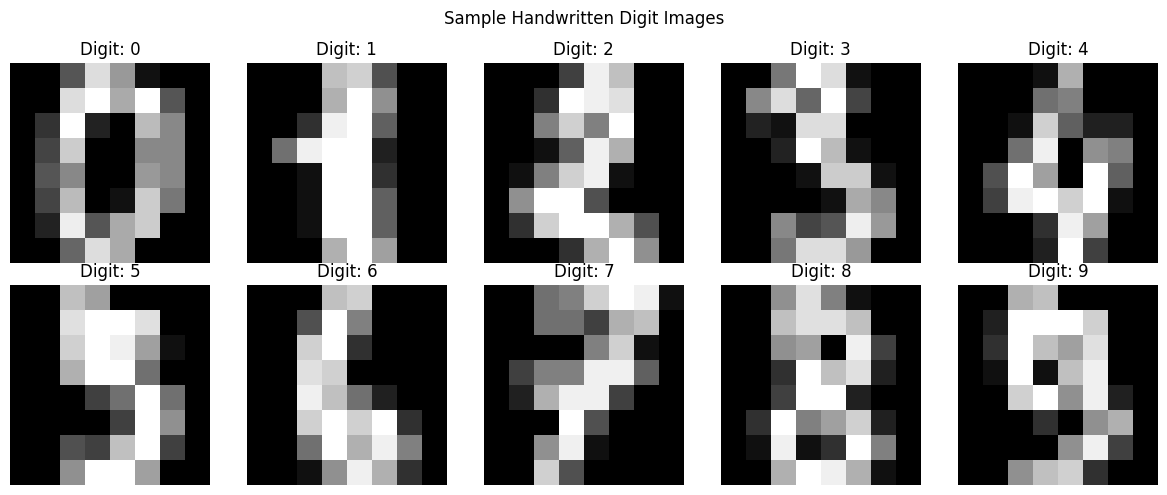

In [2]:
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i], cmap="gray")

    plt.title(f"Digit: {y[i]}")

    plt.axis("off")

plt.suptitle("Sample Handwritten Digit Images")

plt.tight_layout()

plt.show()

Step 4: Display class distribution

Class Distribution:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


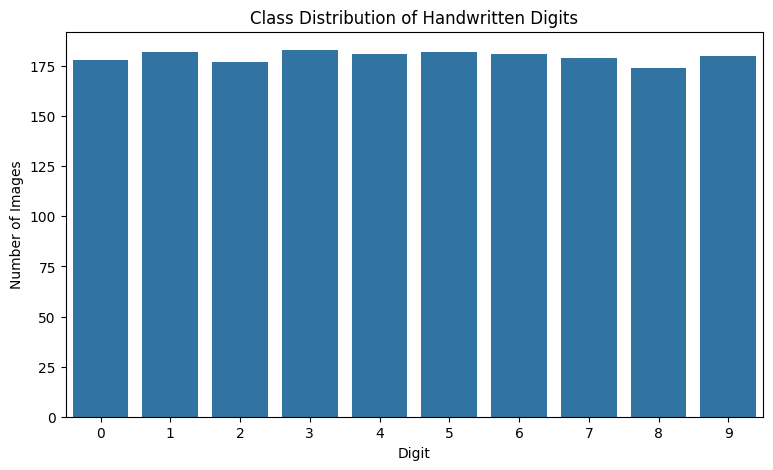

In [3]:
class_counts = pd.Series(y).value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Class Distribution of Handwritten Digits")

plt.xlabel("Digit")
plt.ylabel("Number of Images")

plt.show()

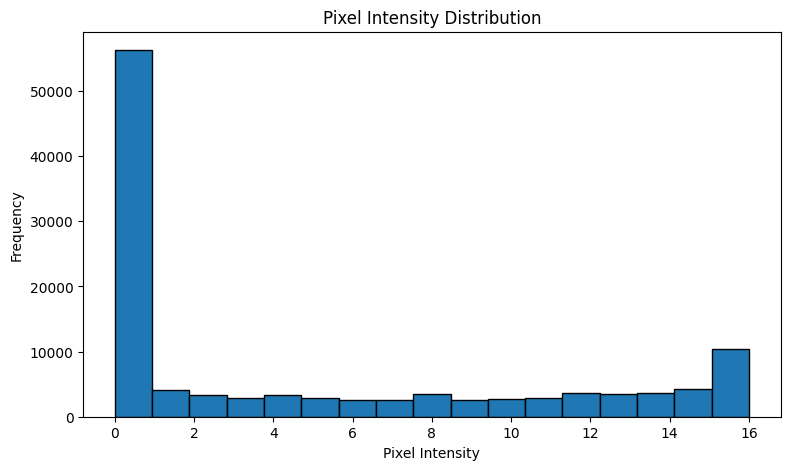

In [4]:
plt.figure(figsize=(9, 5))

plt.hist(
    X.flatten(),
    bins=17,
    edgecolor="black"
)

plt.title("Pixel Intensity Distribution")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

TASK 2 – PREPROCESSING AND TRAIN-TEST SPLIT

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data shape: (1437, 64)
Testing data shape: (360, 64)
Training labels: (1437,)
Testing labels: (360,)


TASK 3 – MODEL DEVELOPMENT AND CROSS-VALIDATION

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [7]:
models = {

    "Dummy Classifier": Pipeline([
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ])

}

print("All three models created successfully!")

All three models created successfully!


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

results = []

for name, model in models.items():

    start_time = time.time()

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    runtime = time.time() - start_time

    results.append({

        "Model": name,

        "CV Accuracy": scores["test_accuracy"].mean(),

        "CV Precision": scores["test_precision"].mean(),

        "CV Recall": scores["test_recall"].mean(),

        "CV F1": scores["test_f1"].mean(),

        "Runtime (seconds)": runtime

    })

results_df = pd.DataFrame(results)

print("Cross-Validation Results:")

display(results_df.round(4))

Cross-Validation Results:


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,Runtime (seconds)
0,Dummy Classifier,0.1009,0.0101,0.1000,0.0183,4.7481
1,KNN,0.9756,0.9767,0.9757,0.9756,0.3949
2,Logistic Regression,0.9680,0.9691,0.9680,0.9679,0.5923


In [9]:
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [10]:
best_model_name = (
    results_df[
        results_df["Model"] != "Dummy Classifier"
    ]
    .sort_values(
        by="CV Accuracy",
        ascending=False
    )
    .iloc[0]["Model"]
)

best_model = models[best_model_name]

print("Selected Best Model:", best_model_name)

Selected Best Model: KNN


TASK 4 – MODEL EVALUATION AND ERROR ANALYSIS

In [11]:
best_model.fit(X_train, y_train)

print("Best model trained successfully!")

Best model trained successfully!


In [12]:
y_pred = best_model.predict(X_test)

print("Predictions generated successfully!")

print("Actual values:", y_test[:10])

print("Predicted values:", y_pred[:10])

Predictions generated successfully!
Actual values: [5 2 8 1 7 2 6 2 6 5]
Predicted values: [5 2 8 1 7 2 6 2 6 5]


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="macro"
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("FINAL MODEL EVALUATION")

print("Selected Model:", best_model_name)

print("Accuracy:", round(accuracy, 4))

print("Macro Precision:", round(precision, 4))

print("Macro Recall:", round(recall, 4))

print("Macro F1 Score:", round(f1, 4))

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

FINAL MODEL EVALUATION
Selected Model: KNN
Accuracy: 0.9639
Macro Precision: 0.9646
Macro Recall: 0.9637
Macro F1 Score: 0.9634

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       0.95      1.00      0.97        35
           3       1.00      0.97      0.99        37
           4       0.97      0.94      0.96        36
           5       0.97      0.97      0.97        37
           6       0.97      1.00      0.99        36
           7       0.92      0.97      0.95        36
           8       0.97      0.89      0.93        35
           9       0.97      0.89      0.93        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



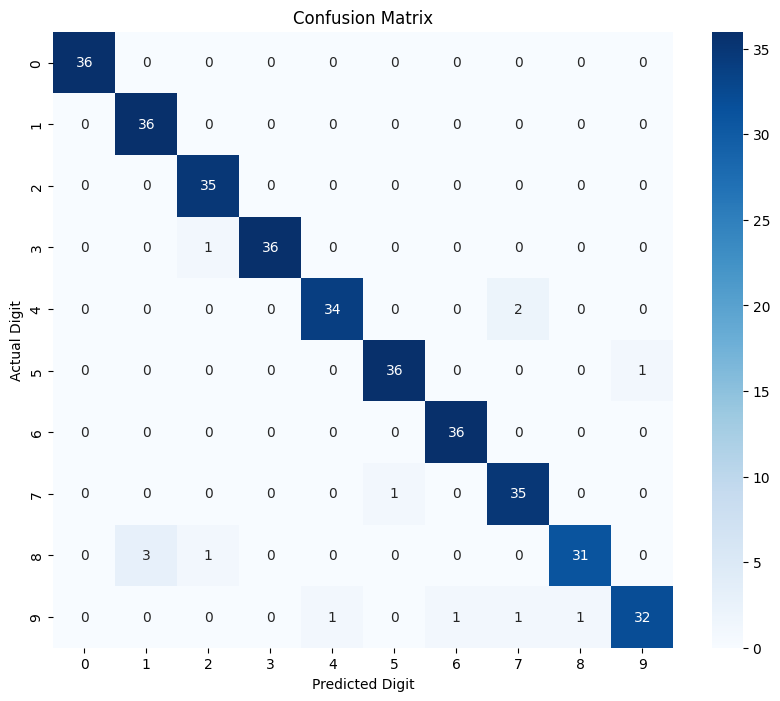

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(10)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)

plt.xlabel("Predicted Digit")

plt.ylabel("Actual Digit")

plt.title("Confusion Matrix")

plt.show()

Total Misclassified Images: 13


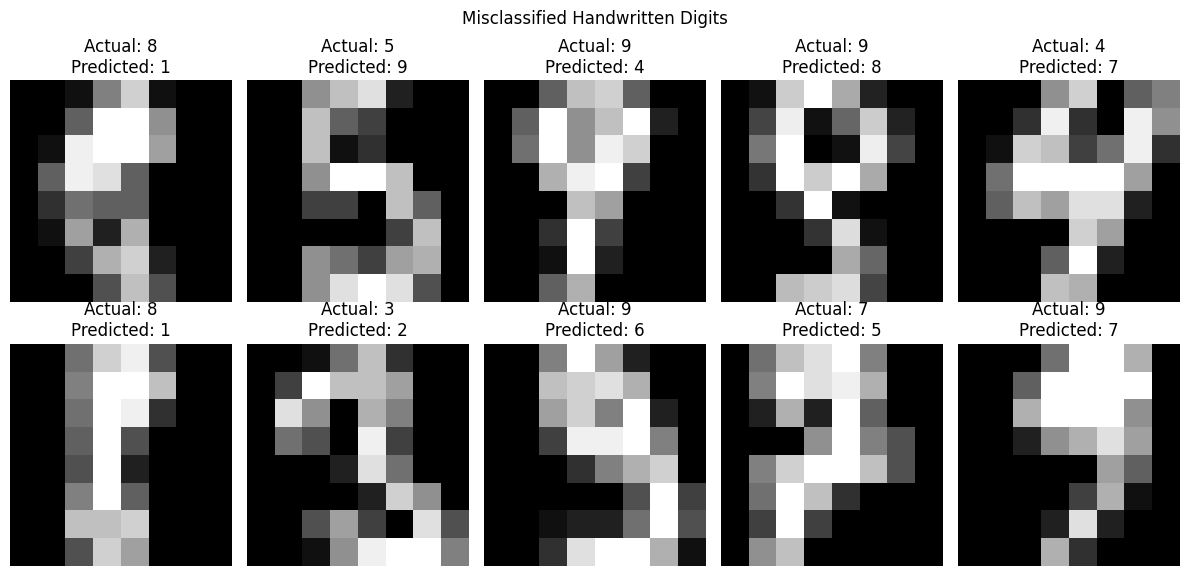

In [15]:
wrong_indices = np.where(y_test != y_pred)[0]

print("Total Misclassified Images:", len(wrong_indices))

if len(wrong_indices) > 0:

    n = min(10, len(wrong_indices))

    plt.figure(figsize=(12, 6))

    for i, idx in enumerate(wrong_indices[:n]):

        plt.subplot(2, 5, i + 1)

        image = X_test[idx].reshape(8, 8)

        plt.imshow(image, cmap="gray")

        plt.title(
            f"Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}"
        )

        plt.axis("off")

    plt.suptitle("Misclassified Handwritten Digits")

    plt.tight_layout()

    plt.show()

else:

    print("No misclassified images found.")

In [16]:
print("Misclassification Patterns:")

for actual in range(10):

    for predicted in range(10):

        if actual != predicted and cm[actual, predicted] > 0:

            print(
                f"Actual {actual} predicted as {predicted}: "
                f"{cm[actual, predicted]} times"
            )

Misclassification Patterns:
Actual 3 predicted as 2: 1 times
Actual 4 predicted as 7: 2 times
Actual 5 predicted as 9: 1 times
Actual 7 predicted as 5: 1 times
Actual 8 predicted as 1: 3 times
Actual 8 predicted as 2: 1 times
Actual 9 predicted as 4: 1 times
Actual 9 predicted as 6: 1 times
Actual 9 predicted as 7: 1 times
Actual 9 predicted as 8: 1 times


TASK 5 – MODEL SERIALIZATION AND INFERENCE

In [17]:
import os

os.makedirs("Handwritten_Digit_Recognition/models", exist_ok=True)
os.makedirs("Handwritten_Digit_Recognition/outputs", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [18]:
import joblib

# Save complete trained pipeline
joblib.dump(
    best_model,
    "Handwritten_Digit_Recognition/models/model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [19]:
import os

model_path = "Handwritten_Digit_Recognition/models/model.joblib"

print("Model exists:", os.path.exists(model_path))

print("Model size:", os.path.getsize(model_path), "bytes")

Model exists: True
Model size: 750126 bytes


In [20]:
import json

final_metrics = {
    "selected_model": best_model_name,
    "accuracy": float(accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1)
}

with open(
    "Handwritten_Digit_Recognition/outputs/final_metrics.json",
    "w"
) as f:

    json.dump(final_metrics, f, indent=4)

print("Evaluation metrics saved successfully!")

Evaluation metrics saved successfully!


In [21]:
results_df.to_csv(
    "Handwritten_Digit_Recognition/outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


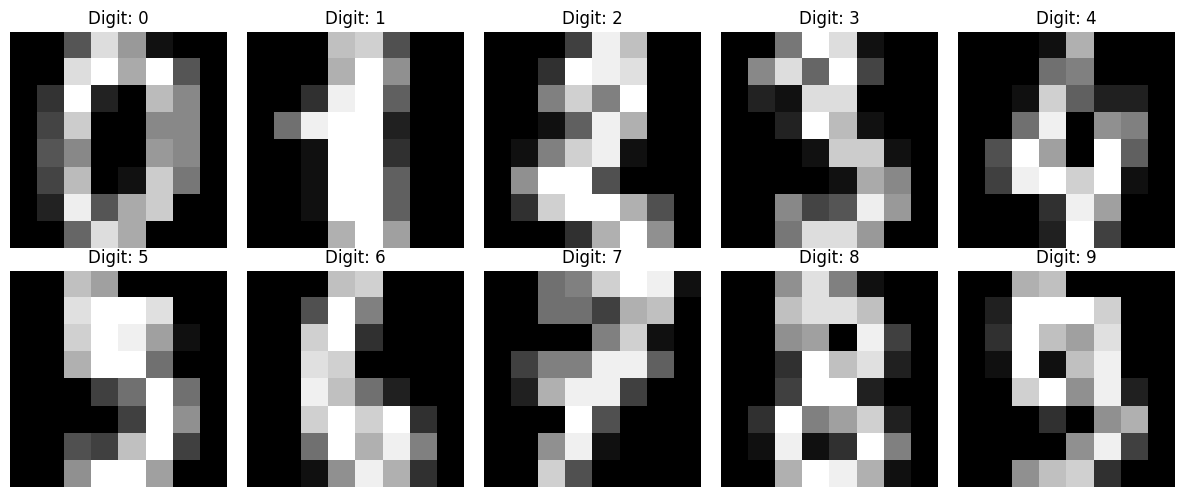

In [22]:
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i], cmap="gray")

    plt.title(f"Digit: {y[i]}")

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "Handwritten_Digit_Recognition/outputs/sample_digits.png"
)

plt.show()

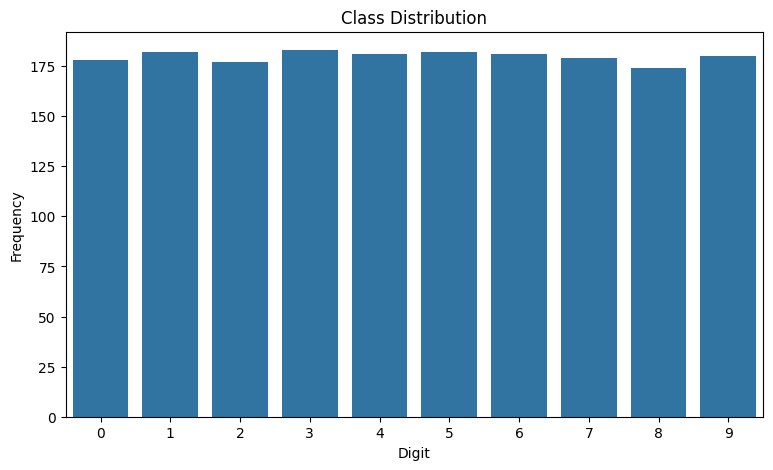

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Class Distribution")
plt.xlabel("Digit")
plt.ylabel("Frequency")

plt.savefig(
    "Handwritten_Digit_Recognition/outputs/class_distribution.png"
)

plt.show()

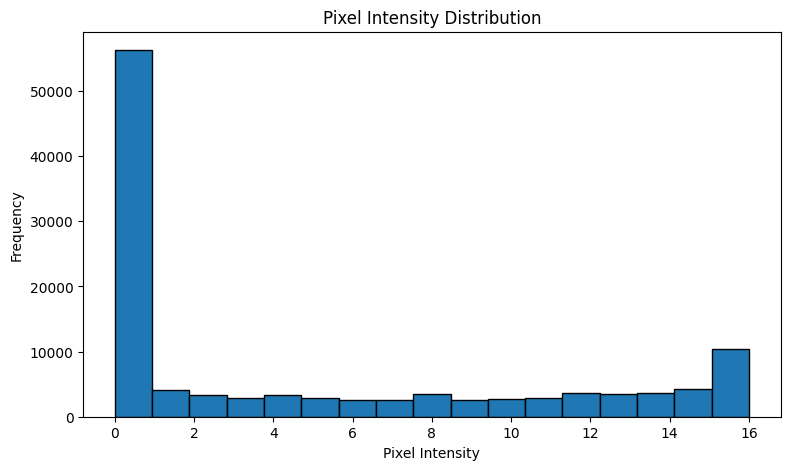

In [24]:
plt.figure(figsize=(9, 5))

plt.hist(X.flatten(), bins=17, edgecolor="black")

plt.title("Pixel Intensity Distribution")

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.savefig(
    "Handwritten_Digit_Recognition/outputs/pixel_distribution.png"
)

plt.show()

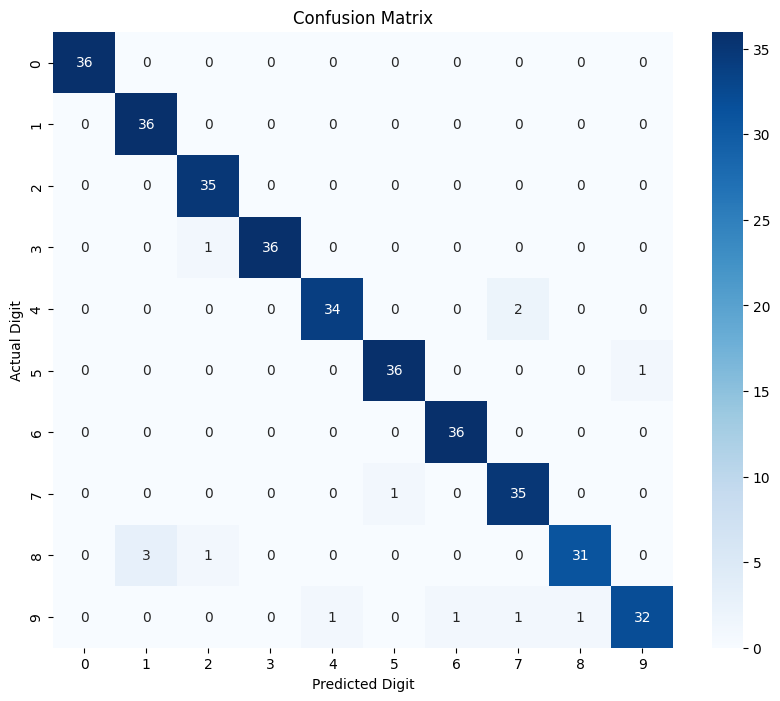

In [25]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.title("Confusion Matrix")

plt.savefig(
    "Handwritten_Digit_Recognition/outputs/confusion_matrix.png"
)

plt.show()

In [32]:
%%writefile Handwritten_Digit_Recognition/predict.py

import sys
import json
import joblib
import numpy as np
from pathlib import Path

# Get the directory where predict.py is located
BASE_DIR = Path(__file__).resolve().parent

# Correct model location
MODEL_PATH = BASE_DIR / "models" / "model.joblib"

def predict_digit(pixel_matrix):

    image = np.asarray(pixel_matrix, dtype=float)

    # Validate dimensions
    if image.shape != (8, 8):
        raise ValueError("Input must be an 8x8 matrix.")

    # Validate pixel values
    if not np.isfinite(image).all():
        raise ValueError("Input contains invalid values.")

    if np.any(image < 0) or np.any(image > 16):
        raise ValueError("Pixel values must be between 0 and 16.")

    # Convert 8x8 image into 64 features
    features = image.reshape(1, 64)

    # Load trained model
    model = joblib.load(MODEL_PATH)

    # Predict digit
    prediction = model.predict(features)[0]

    # Get prediction probabilities
    probabilities = model.predict_proba(features)[0]

    return {
        "predicted_digit": int(prediction),
        "probabilities": {
            str(i): round(float(probabilities[i]), 4)
            for i in range(10)
        }
    }


if __name__ == "__main__":

    if len(sys.argv) != 2:
        print("Usage: python predict.py example_input.json")
        sys.exit(1)

    try:
        with open(sys.argv[1], "r") as f:
            pixel_matrix = json.load(f)

        result = predict_digit(pixel_matrix)
        print(json.dumps(result, indent=4))

    except (ValueError, TypeError) as e:
        print("Invalid Input:", e)

    except FileNotFoundError as e:
        print("File not found:", e)

Overwriting Handwritten_Digit_Recognition/predict.py


In [33]:
example_image = images[0]

print("Actual digit:", y[0])

print("Image matrix:")

print(example_image)

Actual digit: 0
Image matrix:
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


In [34]:
with open(
    "Handwritten_Digit_Recognition/example_input.json",
    "w"
) as f:

    json.dump(example_image.tolist(), f)

print("Example input saved successfully!")

Example input saved successfully!


In [35]:
import sys

sys.path.insert(
    0,
    "Handwritten_Digit_Recognition"
)

from predict import predict_digit

In [36]:
with open(
    "Handwritten_Digit_Recognition/example_input.json",
    "r"
) as f:

    input_image = json.load(f)

In [38]:
result = predict_digit(input_image)

print("Prediction Result:")

print(json.dumps(result, indent=4))

FileNotFoundError: [Errno 2] No such file or directory: 'models/model.joblib'

In [ ]:
import os
from pathlib import Path

print("Current working directory:")
print(os.getcwd())

print("\nModel files found:")

for file in Path(".").rglob("model.joblib"):
    print(file.resolve())

print("\nProject folders:")
print(list(Path(".").glob("*")))

In [39]:
import os

for root, dirs, files in os.walk("/content"):
    if "model.joblib" in files:
        print("Model found at:", os.path.join(root, "model.joblib"))

Model found at: /content/Handwritten_Digit_Recognition/models/model.joblib


In [40]:
import joblib

model_path = "/content/Handwritten_Digit_Recognition/models/model.joblib"

best_model = joblib.load(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [41]:
import numpy as np

def predict_digit(pixel_matrix):

    image = np.asarray(pixel_matrix, dtype=float)

    if image.shape != (8, 8):
        raise ValueError("Input must be an 8x8 matrix.")

    if not np.isfinite(image).all():
        raise ValueError("Invalid pixel values.")

    if np.any(image < 0) or np.any(image > 16):
        raise ValueError("Pixel values must be between 0 and 16.")

    features = image.reshape(1, 64)

    prediction = best_model.predict(features)[0]

    probabilities = best_model.predict_proba(features)[0]

    return {
        "predicted_digit": int(prediction),
        "probabilities": {
            str(i): round(float(probabilities[i]), 4)
            for i in range(10)
        }
    }

In [42]:
result = predict_digit(input_image)

print("Prediction Result:")
print(json.dumps(result, indent=4))

Prediction Result:
{
    "predicted_digit": 0,
    "probabilities": {
        "0": 1.0,
        "1": 0.0,
        "2": 0.0,
        "3": 0.0,
        "4": 0.0,
        "5": 0.0,
        "6": 0.0,
        "7": 0.0,
        "8": 0.0,
        "9": 0.0
    }
}


In [43]:
try:
    predict_digit([[1, 2, 3], [4, 5, 6]])
except ValueError as e:
    print("Validation successful:", e)

Validation successful: Input must be an 8x8 matrix.


In [44]:
invalid_image = np.zeros((8, 8))
invalid_image[0, 0] = 20

try:
    predict_digit(invalid_image)
except ValueError as e:
    print("Validation successful:", e)

Validation successful: Pixel values must be between 0 and 16.


In [45]:
import joblib
import os

os.makedirs("Handwritten_Digit_Recognition/models", exist_ok=True)

joblib.dump(
    best_model,
    "Handwritten_Digit_Recognition/models/model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [46]:
model_path = "Handwritten_Digit_Recognition/models/model.joblib"

print("Model exists:", os.path.exists(model_path))
print("Model size:", os.path.getsize(model_path), "bytes")

Model exists: True
Model size: 750158 bytes


In [47]:
%%writefile Handwritten_Digit_Recognition/requirements.txt
numpy
pandas
matplotlib
seaborn
scikit-learn
joblib

Writing Handwritten_Digit_Recognition/requirements.txt


In [48]:
import os

os.makedirs("Handwritten_Digit_Recognition/outputs", exist_ok=True)

readme = f"""
# Handwritten Digit Recognition

## 1. Project Overview
This project uses Machine Learning to recognize handwritten digits
from grayscale images of size 8x8 pixels.

## 2. Dataset Information
- Dataset: Scikit-learn Digits Dataset
- Total Images: 1797
- Image Dimensions: 8x8
- Features: 64
- Classes: 10 (Digits 0-9)
- Pixel Values: 0 to 16

## 3. Data Preprocessing
- Dataset divided into 80% training and 20% testing.
- Stratified splitting used.
- Random state: 42.
- StandardScaler used where required.
- Pipeline used to prevent data leakage.

## 4. Models Compared
1. Dummy Classifier
2. K-Nearest Neighbors
3. Logistic Regression

## 5. Cross Validation
- StratifiedKFold
- Number of folds: 5
- Shuffle: True
- Random state: 42

## 6. Selected Model
{best_model_name}

## 7. Final Test Performance

- Accuracy: {accuracy:.4f}
- Macro Precision: {precision:.4f}
- Macro Recall: {recall:.4f}
- Macro F1-score: {f1:.4f}

## 8. Error Analysis
A confusion matrix was generated to identify classification errors.
Misclassified images were visualized to understand recurring
confusion patterns between handwritten digits.

## 9. Prediction
The predict.py script:
- Accepts an 8x8 pixel matrix.
- Validates dimensions and pixel values.
- Converts the image into 64 features.
- Loads the saved model.
- Predicts the digit.
- Returns probabilities for all 10 classes.

## 10. Installation

Install dependencies:

pip install -r requirements.txt

## 11. Run Prediction

python predict.py example_input.json

## 12. Limitations
- The model is trained on 8x8 grayscale images.
- Real-world camera images require preprocessing.
- Handwriting variations may affect prediction accuracy.
- Images must be converted to the expected 8x8 pixel format.

## 13. Technologies Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib
"""

with open("Handwritten_Digit_Recognition/README.md", "w") as f:
    f.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [49]:
import json

results_df.to_csv(
    "Handwritten_Digit_Recognition/outputs/model_comparison.csv",
    index=False
)

final_metrics = {
    "selected_model": best_model_name,
    "accuracy": float(accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1)
}

with open(
    "Handwritten_Digit_Recognition/outputs/final_metrics.json",
    "w"
) as f:
    json.dump(final_metrics, f, indent=4)

print("Metrics saved successfully!")

Metrics saved successfully!


In [50]:
import os

for root, dirs, files in os.walk("Handwritten_Digit_Recognition"):
    for file in files:
        print(os.path.join(root, file))

Handwritten_Digit_Recognition/example_input.json
Handwritten_Digit_Recognition/README.md
Handwritten_Digit_Recognition/requirements.txt
Handwritten_Digit_Recognition/predict.py
Handwritten_Digit_Recognition/outputs/pixel_distribution.png
Handwritten_Digit_Recognition/outputs/class_distribution.png
Handwritten_Digit_Recognition/outputs/sample_digits.png
Handwritten_Digit_Recognition/outputs/confusion_matrix.png
Handwritten_Digit_Recognition/outputs/final_metrics.json
Handwritten_Digit_Recognition/outputs/model_comparison.csv
Handwritten_Digit_Recognition/models/model.joblib
Handwritten_Digit_Recognition/__pycache__/predict.cpython-313.pyc


In [51]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "Handwritten_Digit_Recognition",
    "zip",
    root_dir=".",
    base_dir="Handwritten_Digit_Recognition"
)

print("ZIP created successfully!")
files.download(zip_path)

ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>